# 🚀 Practice Day 58

**📅 Date:** 2026-11-06  
📁 Category: Phase 1 · 시각화 기초 (Round 5/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice core chart types (bar, line, and pie) to compare ticket types and show the seasonal pattern across a year
  (막대·선·파이 그래프 등 기본 차트 유형 연습 — 티켓 유형 비교와 연중 계절성 표현)
- Find which ticket type drives the most revenue and when the zoo's busiest months are
  (어떤 티켓 유형이 매출을 가장 많이 견인하는지, 동물원이 가장 붐비는 달은 언제인지 파악하기)

---
# 📂 Dataset

**Dataset Name:** Meridian Zoo — Monthly Ticket Sales by Type (2024) / Meridian Zoo — 티켓 유형별 월간 매출 (2024)

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** 2024 monthly ticket sales for a zoo, covering 5 ticket types (Adult, Child, Senior, Family Pack, Annual Member) — 60 rows total (5 types × 12 months), single table. Visitor counts rise clearly in the spring/summer school-holiday season. Revenue is in USD. Clean — no missing values or duplicates.
(동물원의 2024년 1~12월 티켓 판매 데이터로, 5개 티켓 유형(Adult/Child/Senior/Family Pack/Annual Member)별 월간 방문객 수와 매출을 담고 있습니다(단일 테이블, 60행 = 5유형×12개월). 봄~여름 방학 시즌에 방문객이 뚜렷하게 늘어나며, 매출은 USD 기준이며 결측치·중복 없이 깨끗합니다.)

## Dataset Preview

In [1]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate monthly ticket sales by type for a zoo ---
ticket_types = ['Adult', 'Child', 'Senior', 'Family Pack', 'Annual Member']
avg_price = {'Adult': 25, 'Child': 15, 'Senior': 18, 'Family Pack': 65, 'Annual Member': 8}  # USD per ticket
base_tickets = {'Adult': 2650, 'Child': 3100, 'Senior': 700, 'Family Pack': 820, 'Annual Member': 1500}

months = pd.date_range('2024-01-01', periods=12, freq='MS')
# Seasonal index per month (Jan..Dec): spring/summer school-holiday peak
seasonal = [0.65, 0.7, 0.85, 1.0, 1.15, 1.35, 1.5, 1.4, 0.95, 0.85, 0.75, 1.1]

rows = []
for t in ticket_types:
    for i, m in enumerate(months):
        noise = rng.normal(1.0, 0.07)
        tickets = base_tickets[t] * seasonal[i] * noise
        tickets = max(1, int(round(tickets)))
        revenue = tickets * avg_price[t]  # USD
        rows.append({'month': m, 'ticket_type': t, 'visitors': tickets, 'revenue': revenue})

df = pd.DataFrame(rows).sort_values(['month', 'ticket_type']).reset_index(drop=True)

df.head(10)


,month,ticket_type,visitors,revenue
0,2024-01-01,Adult,1759,43975
1,2024-01-01,Annual Member,1021,8168
2,2024-01-01,Child,2024,30360
3,2024-01-01,Family Pack,529,34385
4,2024-01-01,Senior,441,7938
5,2024-02-01,Adult,1720,43000
6,2024-02-01,Annual Member,1055,8440
7,2024-02-01,Child,2341,35115
8,2024-02-01,Family Pack,540,35100
9,2024-02-01,Senior,478,8604


## Dataset Information

In [2]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   month        60 non-null     datetime64[us]
 1   ticket_type  60 non-null     str           
 2   visitors     60 non-null     int64         
 3   revenue      60 non-null     int64         
dtypes: datetime64[us](1), int64(2), str(1)
memory usage: 2.0 KB

Shape: (60, 4)


,month,ticket_type,visitors,revenue
count,60,60,60.000000,60.000000
unique,NaN,5,NaN,NaN
top,NaN,Adult,NaN,NaN
freq,NaN,12,NaN,NaN
mean,2024-06-16 08:00:00,NaN,1789.116667,38917.616667
min,2024-01-01 00:00:00,NaN,441.000000,7938.000000
25%,2024-03-24 06:00:00,NaN,850.500000,13803.000000
50%,2024-06-16 00:00:00,NaN,1478.500000,39337.500000
75%,2024-09-08 12:00:00,NaN,2517.250000,58738.750000
max,2024-12-01 00:00:00,NaN,4936.000000,100275.000000


---
# ❓ Business Questions

1. **(Analysis)** Which ticket type generates the most total revenue, and which the least?
   (가장 매출이 높은/낮은 티켓 유형은?)
2. **(Analysis)** How does total monthly visitor count (all ticket types combined) change across the year?
   (전체 방문객 수는 월별로 어떻게 변화하는가?)
3. **(Analysis)** What percentage of total annual revenue does each ticket type contribute?
   (티켓 유형별 연간 매출 비중은 각각 몇 %인가?)
4. **(Visualization)** Compare total revenue across all 5 ticket types.
   (5개 티켓 유형의 총매출을 비교하면?)
5. **(Visualization)** Show how total monthly visitor count moves across the year.
   (연중 월별 총 방문객 수는 어떻게 움직이는가?)

---
# 🔍 Data Cleaning Check


In [3]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
month          0
ticket_type    0
visitors       0
revenue        0
dtype: int64

Duplicate rows: 0

Dtypes
month          datetime64[us]
ticket_type               str
visitors                int64
revenue                 int64
dtype: object

Column names
['month', 'ticket_type', 'visitors', 'revenue']

Text columns — unique counts
ticket_type    5
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** Which ticket type generates the most total revenue, and which the least? (가장 매출이 높은/낮은 티켓 유형은?)

**Result:**  
Adult earned the most with **$800,300**, and Annual Member earned the least with **$146,232**.  
(Adult가 **$800,300**으로 매출이 가장 높고, Annual Member가 **$146,232**로 가장 낮습니다.)  

**Insight:**  
Adult earned **$654,068** more than Annual Member. Family Pack is second at **$658,190**.  
(Adult는 Annual Member보다 **$654,068** 더 벌었고, 2위는 Family Pack으로 **$658,190**입니다.)

In [4]:
# Question 1: total revenue by ticket_type (highest / lowest)
revenue_by_ticket_type = df.groupby('ticket_type')['revenue'].sum().sort_values(ascending=False)

revenue_by_ticket_type

ticket_type
Adult            800300
Family Pack      658190
Child            572025
Senior           158310
Annual Member    146232
Name: revenue, dtype: int64

## Question 2

**Question:** How does total monthly visitor count change across the year? (월별 총 방문객 수 변화는?)

**Result:**  
Monthly visitors rise from **5,774** in January to a peak of **13,503** in July, then fall to **6,892** in November and jump to **9,956** in December.  
(월별 방문객은 1월 **5,774**명에서 7월 최고 **13,503**명까지 늘고, 11월 **6,892**명까지 줄었다가 12월에 **9,956**명으로 뜁니다.)  

**Insight:**  
The biggest drop is September at **-31.73%**, and the biggest rise is December at **+44.46%**.  
(가장 큰 하락은 9월 **-31.73%**, 가장 큰 상승은 12월 **+44.46%**입니다.)

In [5]:
# Question 2: total monthly visitor count (all ticket types combined) across the year
monthly_visitors = df.groupby('month')['visitors'].sum().reset_index()
monthly_visitors['previous'] = monthly_visitors['visitors'].shift(1)
monthly_visitors['change'] = monthly_visitors['visitors'] - monthly_visitors['previous']
monthly_visitors['pct_change'] = monthly_visitors['change'] / monthly_visitors['previous'] * 100
monthly_visitors['pct_change'] = monthly_visitors['pct_change'].round(2)

monthly_visitors

,month,visitors,previous,change,pct_change
0,2024-01-01,5774,NaN,NaN,NaN
1,2024-02-01,6134,5774.0,360.0,6.23
2,2024-03-01,7667,6134.0,1533.0,24.99
3,2024-04-01,8879,7667.0,1212.0,15.81
4,2024-05-01,9657,8879.0,778.0,8.76
5,2024-06-01,11257,9657.0,1600.0,16.57
6,2024-07-01,13503,11257.0,2246.0,19.95
7,2024-08-01,12078,13503.0,-1425.0,-10.55
8,2024-09-01,8246,12078.0,-3832.0,-31.73
9,2024-10-01,7304,8246.0,-942.0,-11.42


## Question 3

**Question:** What percentage of total annual revenue does each ticket type contribute? (유형별 연간 매출 비중은?)

**Result:**  
Adult contributes **34.27%** of annual revenue, Family Pack **28.19%**, Child **24.50%**, Senior **6.78%**, and Annual Member **6.26%**.  
(연간 매출 비중은 Adult **34.27%**, Family Pack **28.19%**, Child **24.50%**, Senior **6.78%**, Annual Member **6.26%**입니다.)  

**Insight:**  
Adult and Family Pack together make up **62.46%** of revenue.  
(Adult와 Family Pack을 합치면 매출의 **62.46%**입니다.)

In [6]:
# Question 3: each ticket type's % share of total annual revenue
revenue = df.groupby('ticket_type')['revenue'].sum()

(revenue / revenue.sum() * 100).sort_values(ascending=False).round(2)

ticket_type
Adult            34.27
Family Pack      28.19
Child            24.50
Senior            6.78
Annual Member     6.26
Name: revenue, dtype: float64

---
# 📈 Visualization

**Chart 1:** Bar chart — total revenue by ticket type (막대그래프: 티켓 유형별 총매출)

*Interpretation:*  
Adult has the tallest bar at **$800,300**, and Annual Member the shortest at **$146,232**.  
(Adult 막대가 **$800,300**으로 가장 높고 Annual Member가 **$146,232**로 가장 낮습니다.)  

---

**Chart 2:** Line chart — total monthly visitor trend (선그래프: 월별 총 방문객 추이)

*Interpretation:*  
Visitors climb from **5,774** in January to **13,503** in July, then drop through November and rise again in December.  
(방문객은 1월 **5,774**명에서 7월 **13,503**명까지 오르고, 11월까지 줄었다가 12월에 다시 오릅니다.)


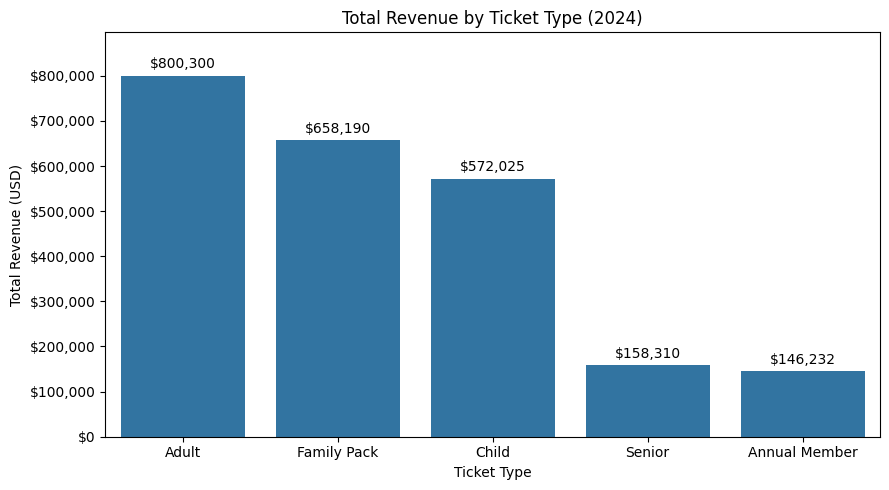

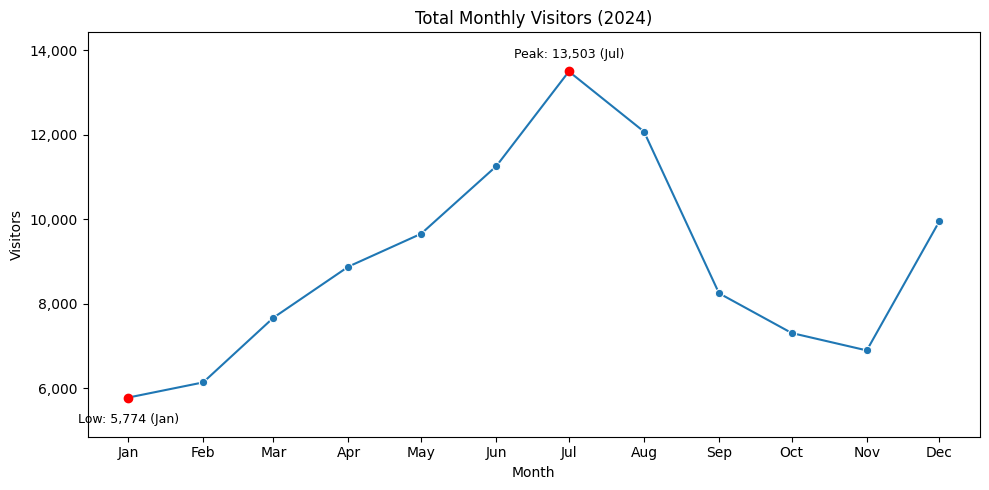

In [7]:
# Visualization
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Chart 1: total revenue by ticket type (bar), same order as the Q1 table
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=revenue_by_ticket_type.index, y=revenue_by_ticket_type.values, ax=ax)
ax.set_title('Total Revenue by Ticket Type (2024)')
ax.set_xlabel('Ticket Type')
ax.set_ylabel('Total Revenue (USD)')
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.bar_label(ax.containers[0], fmt='${:,.0f}', padding=3)
ax.margins(y=0.12)
plt.tight_layout()
plt.show()

# Chart 2: total monthly visitor count across the year (line)
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(x='month', y='visitors', data=monthly_visitors, marker='o', ax=ax)
ax.set_title('Total Monthly Visitors (2024)')
ax.set_xlabel('Month')
ax.set_ylabel('Visitors')
ax.yaxis.set_major_formatter('{x:,.0f}')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

# Mark the peak and the lowest month so the exact values are on the chart
for label, idx, dy in [('Peak', monthly_visitors['visitors'].idxmax(), 10),
                       ('Low', monthly_visitors['visitors'].idxmin(), -18)]:
    row = monthly_visitors.loc[idx]
    ax.scatter(row['month'], row['visitors'], color='red', zorder=3)
    ax.annotate(f"{label}: {row['visitors']:,} ({row['month']:%b})",
                (row['month'], row['visitors']), textcoords='offset points',
                xytext=(0, dy), ha='center', fontsize=9)
ax.margins(y=0.12)
plt.tight_layout()
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- Adult is the top revenue ticket at **$800,300**, and Annual Member is the lowest at **$146,232**.  
  (Adult가 **$800,300**으로 매출 1위이고, Annual Member가 **$146,232**로 가장 낮습니다.)  
- Adult and Family Pack together bring **62.46%** of annual revenue.  
  (Adult와 Family Pack이 연간 매출의 **62.46%**를 차지합니다.)  
- Visitors peak in July at **13,503**, and September falls **-31.73%** from August.  
  (방문객은 7월에 **13,503**명으로 가장 많고, 9월은 8월보다 **-31.73%** 줄어듭니다.)  


---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Protect Adult and Family Pack sales first, since they are **62.46%** of revenue.  
   (매출의 **62.46%**인 Adult와 Family Pack 판매를 먼저 지킵니다.)  
2. Plan staffing around the July peak of **13,503** visitors.  
   (7월 최고 방문객 **13,503**명에 맞춰 인력을 계획합니다.)  
3. Look into what drove the September drop of **-31.73%** and the December rise of **+44.46%**.  
   (9월 **-31.73%** 하락과 12월 **+44.46%** 상승의 원인을 살펴봅니다.)  


---
# ❌ Mistakes
*What mistakes did I make today?*

- In Question 2 I grouped the column `tickets_sold`, but the data column is `visitors`, so it raised a `KeyError`.  
  (Question 2에서 `tickets_sold` 열을 묶었는데 데이터의 열은 `visitors`라서 `KeyError`가 났습니다.)  


---
# ✅ What I Learned
*Today's biggest lesson*

- Check the column names with `df.columns` before a `groupby`.  
  (`groupby` 전에 `df.columns`로 열 이름을 확인합니다.)  
- Set a bar chart's order from the sorted table, and add a title, axis titles, and a USD axis.  
  (막대 순서는 정렬한 표에서 가져오고, 제목, 축 제목, USD 축을 붙입니다.)  


---
# 🧠 Reflection

**What was difficult?**  
Getting Question 2 to run.  
(Question 2를 실행되게 만드는 것)

**Why?**  
The code used `tickets_sold`, which is not a column in the data.  
(코드가 데이터에 없는 `tickets_sold` 열을 썼음)

**How did I solve it?**  
Used the real column `visitors` for the groupby, the change, and the percent change.  
(그룹, 변화량, 변화율에 실제 열 `visitors`를 씀)

**What would I do differently next time?**  
Print `df.columns` before writing a `groupby`.  
(`groupby`를 쓰기 전에 `df.columns`를 출력하기)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★★☆☆  
I can read revenue share and the month-to-month change from the tables.  
(표에서 매출 비중과 전월 대비 변화를 읽을 수 있습니다.)  

**Confidence**  
★★★★★★★☆☆☆  

**Difficulty**  
★★★★☆☆☆☆☆☆  


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Day 59: GroupBy and pivot  
  (Day 59: groupby와 피벗)  
